## PROJETO FIT-BASE

In [1]:
from dotenv import load_dotenv
from sqlalchemy import create_engine
import os

load_dotenv()

engine = create_engine(
    f"postgresql+psycopg2://"
    f"{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}"
    f"/{os.getenv('DB_NAME')}"
)

with engine.connect() as conn:
    from sqlalchemy import text
    result = conn.execute(text("SELECT 1"))
    print("✅ Conexão OK!", result.fetchone())

✅ Conexão OK! (1,)


In [2]:
import pandas as pd

In [3]:
# Carrega as 3 tabelas em DataFrames

exercicios = pd.read_sql("SELECT * FROM exercicios", engine)
treinos = pd.read_sql("SELECT * FROM treinos", engine)
series = pd.read_sql('SELECT * FROM series', engine)

# Confirma o que veio
print("exercicios:", exercicios.shape)
print("treinos:   ", treinos.shape)
print("series:    ", series.shape)

exercicios: (12, 3)
treinos:    (16, 4)
series:     (114, 6)


In [4]:
# Estrutura de cada tabela
print("=== EXERCICIOS ===")
print(exercicios.head())
print("\n=== TREINOS ===")
print(treinos.head())
print("\n=== SERIES ===")
print(series.head())

=== EXERCICIOS ===
   id              nome grupo_muscular
0   2       Supino Reto          Peito
1   3  Supino Inclinado          Peito
2   4         Crucifixo          Peito
3   5       Agachamento         Pernas
4   6         Leg Press         Pernas

=== TREINOS ===
   id        data  duracao_min        observacao
0   2  2026-01-05           45  Aquecimento leve
1   3  2026-01-07           60                  
2   4  2026-01-09           50                  
3   5  2026-01-12           48                  
4   6  2026-01-14           62                  

=== SERIES ===
   id  treino_id  exercicio_id  numero_serie  repeticoes  peso_kg
0   1          2             2             1          10     80.0
1   2          2             2             2           8     90.0
2   3          2             2             3           6     95.0
3   4          2             3             1          10     70.0
4   5          2             3             2           8     75.0


In [5]:
# Juntar as 3 tabelas

df = ( series
.merge(exercicios, left_on='exercicio_id', right_on='id', suffixes=("","_ex"))
.merge(treinos,    left_on="treino_id",    right_on="id", suffixes=("", "_tr"))
)
# Colunas úteis
df = df[["treino_id", "data", "duracao_min", "nome", "grupo_muscular","numero_serie", "repeticoes", "peso_kg"]]

print(df.shape)
print(df.head())

(114, 8)
   treino_id        data  duracao_min              nome grupo_muscular  \
0          2  2026-01-05           45       Supino Reto          Peito   
1          2  2026-01-05           45       Supino Reto          Peito   
2          2  2026-01-05           45       Supino Reto          Peito   
3          2  2026-01-05           45  Supino Inclinado          Peito   
4          2  2026-01-05           45  Supino Inclinado          Peito   

   numero_serie  repeticoes  peso_kg  
0             1          10     80.0  
1             2           8     90.0  
2             3           6     95.0  
3             1          10     70.0  
4             2           8     75.0  


In [6]:
volume = (df.groupby("grupo_muscular")["numero_serie"]
            .count()
            .reset_index()
            .rename(columns={"numero_serie": "total_series"})
            .sort_values("total_series", ascending=False)
)

print(volume)

  grupo_muscular  total_series
3          Peito            36
0         Costas            30
4         Pernas            24
2          Ombro            12
5     Quadriceps             9
1  Isquiotibiais             3


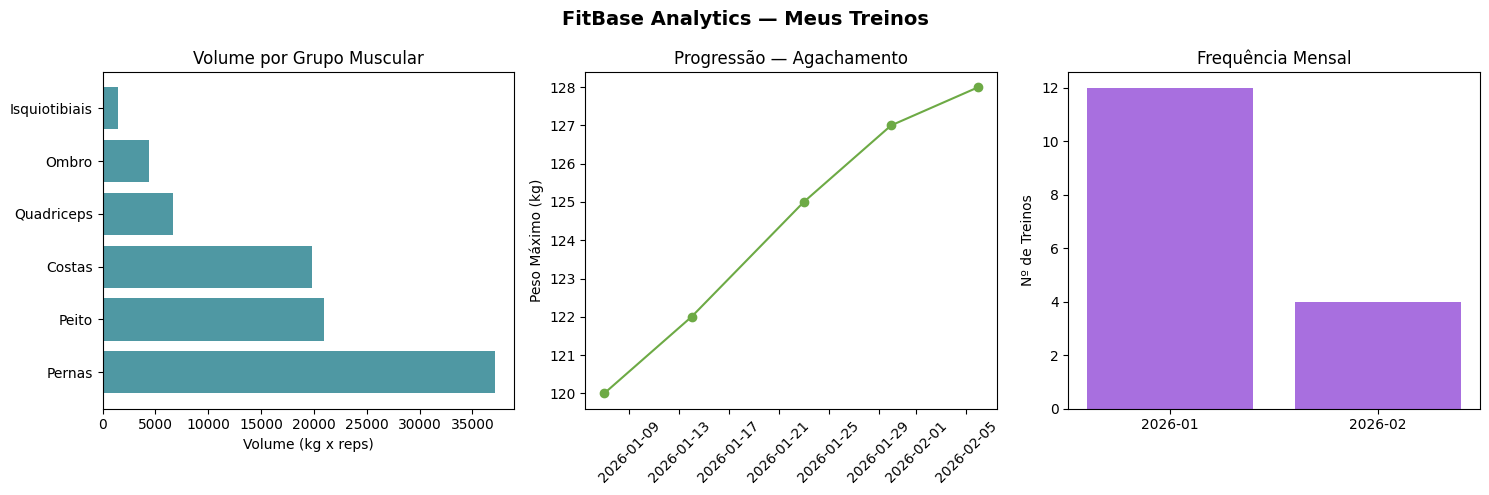

✅ Análise concluída! Gráficos salvos.


In [7]:
from matplotlib import pyplot as plt


df_vol = pd.read_sql("""
    SELECT e.grupo_muscular,
           SUM(s.repeticoes * s.peso_kg) AS volume
    FROM series s
    JOIN exercicios e ON s.exercicio_id = e.id
    GROUP BY e.grupo_muscular
    ORDER BY volume DESC
""", engine)

# ── PERGUNTA 2: Progressão do Agachamento ─────────────
df_squat = pd.read_sql("""
    SELECT t.data, MAX(s.peso_kg) AS peso_max
    FROM series s
    JOIN treinos t    ON s.treino_id = t.id
    JOIN exercicios e ON s.exercicio_id = e.id
    WHERE e.nome = 'Agachamento'
    GROUP BY t.data ORDER BY t.data
""", engine)

# ── PERGUNTA 3: Treinos por mês ───────────────────────
df_mes = pd.read_sql("""
    SELECT TO_CHAR(data, 'YYYY-MM') AS mes,
        COUNT(*) AS num_treinos
    FROM treinos
    GROUP BY mes ORDER BY mes
""", engine)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('FitBase Analytics — Meus Treinos', fontsize=14, fontweight='bold')

# Gráfico 1: Volume por grupo muscular
axes[0].barh(df_vol['grupo_muscular'], df_vol['volume'], color='#4f98a3')
axes[0].set_title('Volume por Grupo Muscular')
axes[0].set_xlabel('Volume (kg x reps)')

# Gráfico 2: Progressão do Agachamento
axes[1].plot(df_squat['data'], df_squat['peso_max'], 'o-', color='#6daa45')
axes[1].set_title('Progressão — Agachamento')
axes[1].set_ylabel('Peso Máximo (kg)')
axes[1].tick_params(axis='x', rotation=45)

# Gráfico 3: Treinos por mês
axes[2].bar(df_mes['mes'], df_mes['num_treinos'], color='#a86fdf')
axes[2].set_title('Frequência Mensal')
axes[2].set_ylabel('Nº de Treinos')

plt.tight_layout()
plt.savefig('assets/analise_treinos.png', dpi=150)
plt.show()
print("✅ Análise concluída! Gráficos salvos.")

In [8]:
from dotenv import load_dotenv
import os

load_dotenv()

print(os.getenv("DB_NAME"))
print(os.getenv("DB_USER"))    # fituser
print(os.getenv("DB_PASSWORD") is not None)  

fitbase
fituser
True


## Revisão — JOINs, Subqueries, GROUP BY, CTE, ROW_NUMBER, RANK

In [9]:
# INNER JOIN — visão completa das séries com exercício e data do treino
q = """
SELECT
  t.data,
  e.nome,
  e.grupo_muscular,
  s.numero_serie,
  s.repeticoes,
  s.peso_kg
FROM series s
INNER JOIN exercicios e ON s.exercicio_id = e.id
INNER JOIN treinos t ON s.treino_id = t.id
ORDER BY t.data, e.nome, s.numero_serie
"""
pd.read_sql(q, engine)

,data,nome,grupo_muscular,numero_serie,repeticoes,peso_kg
0,2026-01-05,Crucifixo,Peito,1,12,20.0
1,2026-01-05,Crucifixo,Peito,2,12,22.0
2,2026-01-05,Crucifixo,Peito,3,10,24.0
3,2026-01-05,Supino Inclinado,Peito,1,10,70.0
4,2026-01-05,Supino Inclinado,Peito,2,8,75.0
...,...,...,...,...,...,...
109,2026-02-09,Puxada Frente,Costas,2,12,72.0
110,2026-02-09,Puxada Frente,Costas,3,10,72.0
111,2026-02-09,Remada Curvada,Costas,1,10,77.0
112,2026-02-09,Remada Curvada,Costas,2,10,82.0


In [10]:
# LEFT JOIN — exercícios cadastrados que nunca foram executados
q = """
SELECT e.nome, e.grupo_muscular
FROM exercicios e
LEFT JOIN series s ON e.id = s.exercicio_id
WHERE s.id IS NULL
"""
pd.read_sql(q, engine)

,nome,grupo_muscular


In [11]:
# Subquery — treinos com duração acima da média
q = """
SELECT id, data, duracao_min
FROM treinos
WHERE duracao_min > (
  SELECT AVG(duracao_min) FROM treinos
)
"""
pd.read_sql(q, engine)

,id,data,duracao_min
0,3,2026-01-07,60
1,6,2026-01-14,62
2,10,2026-01-23,65
3,13,2026-01-30,60
4,16,2026-02-06,63


In [12]:
# HAVING — exercícios com 3 ou mais séries registradas
q = """
SELECT exercicio_id, COUNT(*) AS total_series, SUM(repeticoes) AS total_reps
FROM series
GROUP BY exercicio_id
HAVING COUNT(*) >= 3
"""
pd.read_sql(q, engine)

,exercicio_id,total_series,total_reps
0,6,9,102
1,12,6,60
2,3,9,82
3,11,3,34
4,8,12,112
5,13,6,78
6,10,6,64
7,9,12,134
8,7,9,117
9,5,15,120


In [13]:
# GROUP BY — total de séries por exercício com nome
q = """
SELECT e.nome, e.grupo_muscular, COUNT(s.id) AS total_series
FROM exercicios e
JOIN series s ON e.id = s.exercicio_id
GROUP BY e.id, e.nome, e.grupo_muscular
ORDER BY total_series DESC
"""
pd.read_sql(q, engine)

,nome,grupo_muscular,total_series
0,Supino Reto,Peito,15
1,Agachamento,Pernas,15
2,Puxada Frente,Costas,12
3,Remada Curvada,Costas,12
4,Crucifixo,Peito,12
5,Extensora,Quadriceps,9
6,Supino Inclinado,Peito,9
7,Leg Press,Pernas,9
8,Remada Unilateral,Costas,6
9,Elevação Lateral,Ombro,6


In [14]:
# Filtro por data — treinos de janeiro de 2026
q = """
SELECT id, data, duracao_min
FROM treinos
WHERE data >= '2026-01-01' AND data <= '2026-01-31'
"""
pd.read_sql(q, engine)

,id,data,duracao_min
0,2,2026-01-05,45
1,3,2026-01-07,60
2,4,2026-01-09,50
3,5,2026-01-12,48
4,6,2026-01-14,62
5,7,2026-01-16,52
6,8,2026-01-19,45
7,9,2026-01-21,46
8,10,2026-01-23,65
9,11,2026-01-26,50


In [15]:
# EXTRACT — total de treinos e duração média por mês
q = """
SELECT
  EXTRACT(MONTH FROM data) AS mes,
  COUNT(*) AS total_treinos,
  ROUND(AVG(duracao_min), 2) AS media_duracao
FROM treinos
GROUP BY EXTRACT(MONTH FROM data)
ORDER BY mes
"""
pd.read_sql(q, engine)

,mes,total_treinos,media_duracao
0,1.0,12,52.58
1,2.0,4,53.00


In [16]:
# CTE — resumo por exercício (total de séries, reps e peso médio)
q = """
WITH resumo_por_exercicio AS (
  SELECT
    exercicio_id,
    COUNT(*) AS total_series,
    SUM(repeticoes) AS total_reps,
    ROUND(AVG(peso_kg), 2) AS media_peso
  FROM series
  GROUP BY exercicio_id
)
SELECT
  e.nome,
  e.grupo_muscular,
  r.total_series,
  r.total_reps,
  r.media_peso
FROM resumo_por_exercicio r
JOIN exercicios e ON e.id = r.exercicio_id
ORDER BY r.total_reps DESC
"""
pd.read_sql(q, engine)

,nome,grupo_muscular,total_series,total_reps,media_peso
0,Crucifixo,Peito,12,136,24.50
1,Puxada Frente,Costas,12,134,67.00
2,Supino Reto,Peito,15,126,91.73
3,Agachamento,Pernas,15,120,116.13
4,Extensora,Quadriceps,9,117,57.22
5,Remada Curvada,Costas,12,112,78.58
6,Leg Press,Pernas,9,102,230.00
7,Supino Inclinado,Peito,9,82,75.33
8,Elevação Lateral,Ombro,6,78,14.33
9,Remada Unilateral,Costas,6,64,33.00


In [17]:
# ROW_NUMBER + RANK — posição dentro do grupo muscular e ranking geral
q = """
SELECT
  e.nome,
  e.grupo_muscular,
  SUM(s.repeticoes) AS total_reps,
  ROW_NUMBER() OVER (PARTITION BY e.grupo_muscular ORDER BY SUM(s.repeticoes) DESC) AS posicao_no_grupo,
  RANK()       OVER (ORDER BY SUM(s.repeticoes) DESC) AS ranking_geral
FROM series s
JOIN exercicios e ON e.id = s.exercicio_id
GROUP BY e.id, e.nome, e.grupo_muscular
ORDER BY e.grupo_muscular, posicao_no_grupo
"""
pd.read_sql(q, engine)

,nome,grupo_muscular,total_reps,posicao_no_grupo,ranking_geral
0,Puxada Frente,Costas,134,1,2
1,Remada Curvada,Costas,112,2,6
2,Remada Unilateral,Costas,64,3,10
3,Flexora,Isquiotibiais,34,1,12
4,Elevação Lateral,Ombro,78,1,9
5,Desenvolvimento,Ombro,60,2,11
6,Crucifixo,Peito,136,1,1
7,Supino Reto,Peito,126,2,3
8,Supino Inclinado,Peito,82,3,8
9,Agachamento,Pernas,120,1,4


## Dia 4 — Window Functions: LAG, LEAD, DENSE_RANK, NTILE

In [18]:
# LAG + COALESCE — evolução de carga por exercício
q = """
SELECT
  t.data,
  e.nome AS exercicio,
  ROUND(AVG(s.peso_kg)::NUMERIC, 2) AS peso_medio,
  COALESCE(
    LAG(ROUND(AVG(s.peso_kg)::NUMERIC, 2)) OVER (
      PARTITION BY e.nome ORDER BY t.data
    ),
    ROUND(AVG(s.peso_kg)::NUMERIC, 2)
  ) AS peso_treino_anterior
FROM series s
JOIN exercicios e ON s.exercicio_id = e.id
JOIN treinos   t ON s.treino_id    = t.id
GROUP BY t.data, e.nome
ORDER BY e.nome, t.data
"""
pd.read_sql(q, engine)

,data,exercicio,peso_medio,peso_treino_anterior
0,2026-01-07,Agachamento,110.00,110.00
1,2026-01-14,Agachamento,114.00,110.00
2,2026-01-23,Agachamento,117.00,114.00
3,2026-01-30,Agachamento,119.00,117.00
4,2026-02-06,Agachamento,120.67,119.00
5,2026-01-05,Crucifixo,22.00,22.00
6,2026-01-12,Crucifixo,23.33,22.00
7,2026-01-21,Crucifixo,25.33,23.33
8,2026-02-04,Crucifixo,27.33,25.33
9,2026-01-19,Desenvolvimento,55.00,55.00


In [19]:
# LEAD — intervalo de dias entre treinos consecutivos
q = """
SELECT
  t.id,
  t.data,
  t.duracao_min,
  LEAD(t.data) OVER (ORDER BY t.data) AS proximo_treino,
  LEAD(t.data) OVER (ORDER BY t.data) - t.data AS dias_ate_proximo
FROM treinos t
ORDER BY t.data
"""
pd.read_sql(q, engine)

,id,data,duracao_min,proximo_treino,dias_ate_proximo
0,2,2026-01-05,45,2026-01-07,2.0
1,3,2026-01-07,60,2026-01-09,2.0
2,4,2026-01-09,50,2026-01-12,3.0
3,5,2026-01-12,48,2026-01-14,2.0
4,6,2026-01-14,62,2026-01-16,2.0
5,7,2026-01-16,52,2026-01-19,3.0
6,8,2026-01-19,45,2026-01-21,2.0
7,9,2026-01-21,46,2026-01-23,2.0
8,10,2026-01-23,65,2026-01-26,3.0
9,11,2026-01-26,50,2026-01-28,2.0


In [20]:
# RANK vs DENSE_RANK — ranking de exercícios por volume total
q = """
WITH volume AS (
  SELECT
    e.nome,
    e.grupo_muscular,
    SUM(s.peso_kg * s.repeticoes) AS volume_total
  FROM series s
  JOIN exercicios e ON s.exercicio_id = e.id
  GROUP BY e.nome, e.grupo_muscular
)
SELECT
  nome,
  grupo_muscular,
  ROUND(volume_total::NUMERIC, 1) AS volume_total,
  RANK()       OVER (ORDER BY volume_total DESC) AS rank_com_lacuna,
  DENSE_RANK() OVER (ORDER BY volume_total DESC) AS dense_rank
FROM volume
ORDER BY volume_total DESC
"""
pd.read_sql(q, engine)

,nome,grupo_muscular,volume_total,rank_com_lacuna,dense_rank
0,Leg Press,Pernas,23340.0,1,1
1,Agachamento,Pernas,13762.0,2,2
2,Supino Reto,Peito,11451.0,3,3
3,Puxada Frente,Costas,8968.0,4,4
4,Remada Curvada,Costas,8762.0,5,5
5,Extensora,Quadriceps,6669.0,6,6
6,Supino Inclinado,Peito,6164.0,7,7
7,Crucifixo,Peito,3324.0,8,8
8,Desenvolvimento,Ombro,3320.0,9,9
9,Remada Unilateral,Costas,2104.0,10,10


In [21]:
# NTILE(4) — classifica treinos em quartis de intensidade
q = """
WITH intensidade AS (
  SELECT
    t.id,
    t.data,
    t.duracao_min,
    SUM(s.peso_kg * s.repeticoes) AS volume_total
  FROM series s
  JOIN treinos t ON s.treino_id = t.id
  GROUP BY t.id, t.data, t.duracao_min
)
SELECT
  id,
  data,
  duracao_min,
  ROUND(volume_total::NUMERIC, 1) AS volume_total,
  NTILE(4) OVER (ORDER BY volume_total) AS quartil
FROM intensidade
ORDER BY volume_total
"""
pd.read_sql(q, engine)

,id,data,duracao_min,volume_total,quartil
0,8,2026-01-19,45,2146.0,1
1,14,2026-02-02,47,2284.0,1
2,9,2026-01-21,46,3236.0,1
3,15,2026-02-04,50,3268.0,1
4,11,2026-01-26,50,4550.0,2
5,12,2026-01-28,48,4570.0,2
6,17,2026-02-09,52,4674.0,2
7,2,2026-01-05,45,4734.0,2
8,10,2026-01-23,65,5015.0,3
9,4,2026-01-09,50,5130.0,3


## Dia 5 — CASE, CTE e agregações avançadas

In [22]:
# Classificar a duração dos treinas em faixas
q = """
SELECT 
    id,
    data,duracao_min,
    CASE
        WHEN duracao_min < 30 THEN 'Curto'
        WHEN duracao_min BETWEEN 30 AND 59 THEN 'Médio'
        ELSE 'Longo'
    END AS faixa_duracao
FROM treinos
ORDER BY data;

"""
pd.read_sql(q, engine)

,id,data,duracao_min,faixa_duracao
0,2,2026-01-05,45,Médio
1,3,2026-01-07,60,Longo
2,4,2026-01-09,50,Médio
3,5,2026-01-12,48,Médio
4,6,2026-01-14,62,Longo
5,7,2026-01-16,52,Médio
6,8,2026-01-19,45,Médio
7,9,2026-01-21,46,Médio
8,10,2026-01-23,65,Longo
9,11,2026-01-26,50,Médio


In [23]:
# Classificar de acordo com volume

q = """
SELECT
    treino_id,
    exercicio_id,
    repeticoes,
    peso_kg,
    (repeticoes * peso_kg) AS volume,
    CASE
        WHEN (repeticoes * peso_kg) > 1000 THEN 'Alto'
        WHEN (repeticoes * peso_kg) BETWEEN 500 AND 999 THEN 'Médio'
        ELSE 'Baixo'
    END AS faixa_volume    
FROM series
ORDER BY volume DESC;
"""
pd.read_sql(q, engine)

,treino_id,exercicio_id,repeticoes,peso_kg,volume,faixa_volume
0,13,6,12,240.0,2880.0,Alto
1,6,6,12,230.0,2760.0,Alto
2,3,6,12,220.0,2640.0,Alto
3,13,6,12,220.0,2640.0,Alto
4,13,6,10,260.0,2600.0,Alto
...,...,...,...,...,...,...
109,14,13,12,16.0,192.0,Baixo
110,14,13,12,16.0,192.0,Baixo
111,8,13,15,12.0,180.0,Baixo
112,8,13,12,14.0,168.0,Baixo


In [24]:
# JOIN exercicios e ON s.exercicio_id = e.id
q = """
WITH volume_exercicio AS (
    SELECT 
        e.nome,
        s.treino_id,
        s.exercicio_id,
        s.repeticoes,
        s.peso_kg,
        (s.repeticoes * s.peso_kg) AS volume,
        CASE
            WHEN (repeticoes * peso_kg) >= 1000 THEN 'Alto'
            WHEN (repeticoes * peso_kg) BETWEEN 500 AND 999 THEN 'Médio'
            ELSE 'Baixo'
        END AS faixa_volume    
    FROM series s 
    JOIN exercicios e ON s.exercicio_id = e.id 
)
SELECT
    treino_id,
    nome,
    exercicio_id
    repeticoes,
    peso_kg,
    volume,
    faixa_volume
    
FROM volume_exercicio  
ORDER BY volume DESC;
"""
pd.read_sql(q, engine)

,treino_id,nome,repeticoes,peso_kg,volume,faixa_volume
0,13,Leg Press,6,240.0,2880.0,Alto
1,6,Leg Press,6,230.0,2760.0,Alto
2,3,Leg Press,6,220.0,2640.0,Alto
3,13,Leg Press,6,220.0,2640.0,Alto
4,13,Leg Press,6,260.0,2600.0,Alto
...,...,...,...,...,...,...
109,14,Elevação Lateral,13,16.0,192.0,Baixo
110,14,Elevação Lateral,13,16.0,192.0,Baixo
111,8,Elevação Lateral,13,12.0,180.0,Baixo
112,8,Elevação Lateral,13,14.0,168.0,Baixo


In [25]:
# JOIN exercicios e ON s.exercicio_id = e.id
q = """
WITH volume_exercicio AS (
    SELECT 
        e.nome,
        s.treino_id,
        s.exercicio_id,
        s.repeticoes,
        s.peso_kg,
        (s.repeticoes * s.peso_kg) AS volume,
        CASE
            WHEN (repeticoes * peso_kg) >= 1000 THEN 'Alto'
            WHEN (repeticoes * peso_kg) BETWEEN 500 AND 999 THEN 'Médio'
            ELSE 'Baixo'
        END AS faixa_volume    
    FROM series s 
    JOIN exercicios e ON s.exercicio_id = e.id 
)
SELECT
    nome,
    SUM(volume) AS volume_total,
    COUNT(*) AS qtd_series
FROM volume_exercicio  
GROUP BY nome
ORDER BY volume_total DESC;
"""
df_resumo = pd.read_sql(q, engine)
df_resumo

,nome,volume_total,qtd_series
0,Leg Press,23340.0,9
1,Agachamento,13762.0,15
2,Supino Reto,11451.0,15
3,Puxada Frente,8968.0,12
4,Remada Curvada,8762.0,12
5,Extensora,6669.0,9
6,Supino Inclinado,6164.0,9
7,Crucifixo,3324.0,12
8,Desenvolvimento,3320.0,6
9,Remada Unilateral,2104.0,6


In [26]:
q = """
WITH volume_exercicio AS (
    SELECT 
        e.nome,
        s.treino_id,
        s.exercicio_id,
        s.repeticoes,
        s.peso_kg,
        (s.repeticoes * s.peso_kg) AS volume,
        CASE
            WHEN (repeticoes * peso_kg) >= 1000 THEN 'Alto'
            WHEN (repeticoes * peso_kg) BETWEEN 500 AND 999 THEN 'Médio'
            ELSE 'Baixo'
        END AS faixa_volume    
    FROM series s 
    JOIN exercicios e ON s.exercicio_id = e.id 
)
SELECT
    nome,
    COUNT(*) AS qtd_series_alto,
    SUM(volume) AS volume_total_alto
FROM volume_exercicio
WHERE faixa_volume = 'Alto'
GROUP BY nome
ORDER BY volume_total_alto DESC;
"""
df_alto = pd.read_sql(q, engine)
df_alto

,nome,qtd_series_alto,volume_total_alto
0,Leg Press,9,23340.0
1,Agachamento,5,5350.0


## Dia 6 — Gráficos com Seaborn + Matplotlib

In [27]:
q = """

SELECT
    t.data,
    e.nome AS exercicio,
    AVG(s.peso_kg) as peso_medio
FROM series s
JOIN exercicios e ON e.id = s.exercicio_id
JOIN treinos t ON t.id = s.treino_id
GROUP BY t.data, e.nome
ORDER BY t.data, e.nome;

"""
df_evolucao = pd.read_sql(q, engine)
df_evolucao.head()

,data,exercicio,peso_medio
0,2026-01-05,Crucifixo,22.000000
1,2026-01-05,Supino Inclinado,73.333333
2,2026-01-05,Supino Reto,88.333333
3,2026-01-07,Agachamento,110.000000
4,2026-01-07,Extensora,53.333333


In [28]:
df_evolucao[df_evolucao['exercicio'] == 'Supino Reto']

,data,exercicio,peso_medio
2,2026-01-05,Supino Reto,88.333333
11,2026-01-12,Supino Reto,90.333333
21,2026-01-21,Supino Reto,92.000000
27,2026-01-28,Supino Reto,93.333333
33,2026-02-04,Supino Reto,94.666667


In [29]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


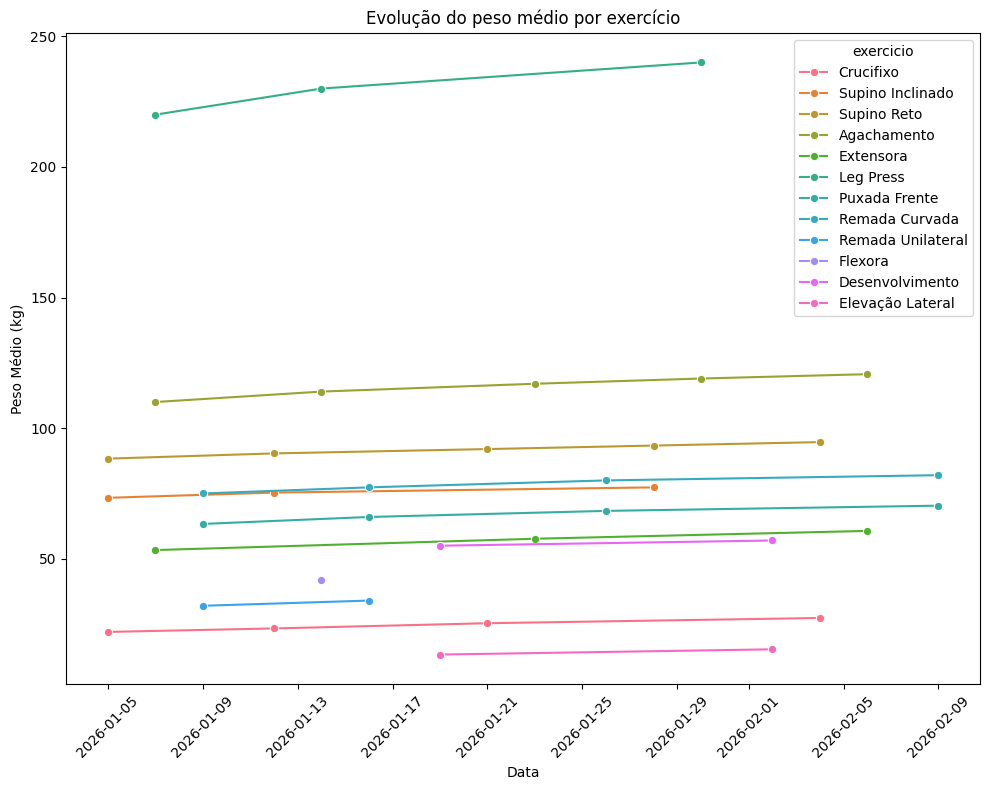

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.lineplot(
    data=df_evolucao,
    x='data',
    y='peso_medio',
    hue='exercicio',
    marker='o'
)
plt.title('Evolução do peso médio por exercício')
plt.xlabel('Data')
plt.ylabel('Peso Médio (kg)')
plt.xticks(rotation=45)
plt.tight_layout()

In [31]:
q_volume = """
SELECT
    e.grupo_muscular,
    SUM(s.peso_kg * s.repeticoes) AS volume_total
FROM series s
JOIN  exercicios e ON e.id = s.exercicio_id
GROUP BY e.grupo_muscular
ORDER BY volume_total DESC;

"""
df_volume = pd.read_sql(q_volume, engine)
df_volume

,grupo_muscular,volume_total
0,Pernas,37102.0
1,Peito,20939.0
2,Costas,19834.0
3,Quadriceps,6669.0
4,Ombro,4430.0
5,Isquiotibiais,1424.0


C:\Users\User\AppData\Local\Temp\ipykernel_10820\537424049.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


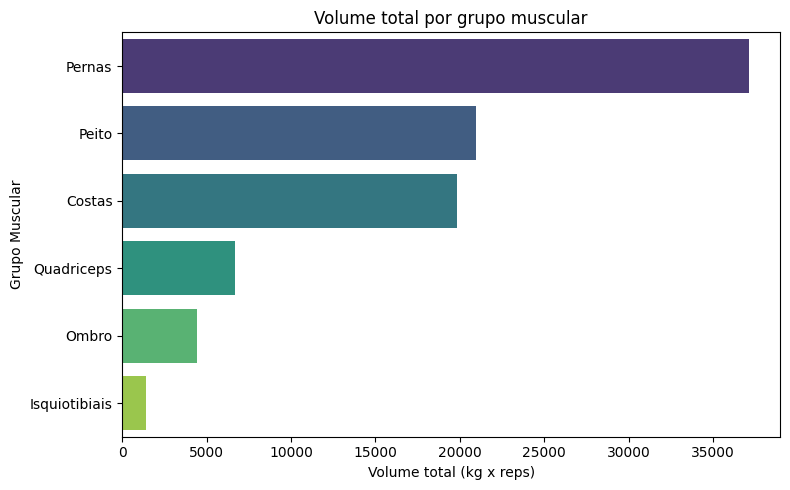

In [32]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=df_volume,
    x='volume_total',
    y='grupo_muscular',
    orient='h',
    palette='viridis'
)
plt.title('Volume total por grupo muscular')
plt.xlabel('Volume total (kg x reps)')
plt.ylabel('Grupo Muscular')
plt.tight_layout()
plt.show()

In [33]:
q_corr = """
SELECT
    s.repeticoes,
    s.peso_kg,
    s.numero_serie,
    t.duracao_min,
    (s.peso_kg * s.repeticoes) AS volume_serie
FROM series s
JOIN treinos t ON t.id = s.treino_id;
"""
df_corr = pd.read_sql(q_corr, engine)
df_corr.head()

,repeticoes,peso_kg,numero_serie,duracao_min,volume_serie
0,10,80.0,1,45,800.0
1,8,90.0,2,45,720.0
2,6,95.0,3,45,570.0
3,10,70.0,1,45,700.0
4,8,75.0,2,45,600.0


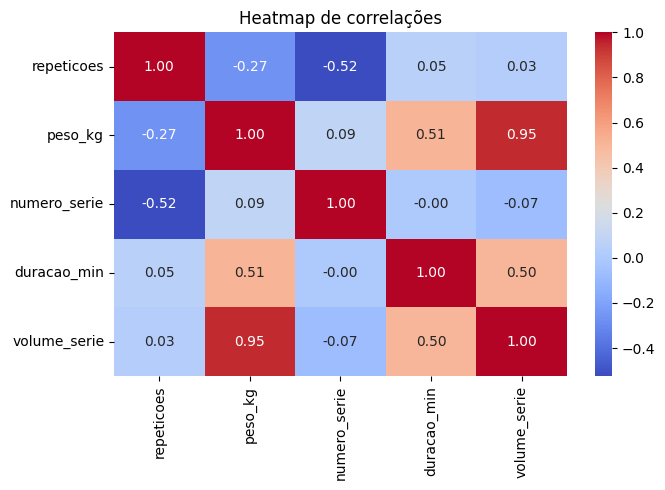

In [34]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    df_corr.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)
plt.title('Heatmap de correlações')
plt.tight_layout()
plt.show()

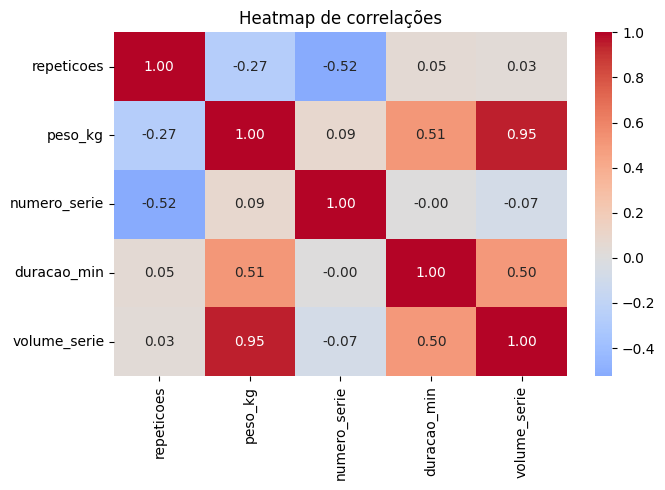

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.heatmap(
    df_corr.corr(numeric_only=True),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)
plt.title('Heatmap de correlações')
plt.tight_layout()
plt.show()

## Conclusões do Dia 6 (Análise Exploratória Visual)

A partir das visualizações geradas, extraímos os seguintes insights:

1. **Progressão de Carga:** Exercícios compostos como Leg Press e Supino Reto apresentam uma clara tendência ascendente, indicando evolução consistente de força.
2. **Desequilíbrio de Volume:** O grupo "Pernas" concentra quase o dobro do volume de "Peito" e "Costas".
3. **Padrão de Intensidade:** O heatmap confirmou matematicamente (0.95) que o incremento de peso é o principal impulsionador do volume total da série. A relação inversa entre peso e repetições existe (-0.27), mas é estatisticamente fraca neste recorte.

**⚠️ Limitação dos Dados:** 
Exercícios como Flexora e Elevação Lateral possuem pouquíssimos pontos de dados (1 a 2 registros). Não é possível afirmar se o atleta negligencia essas áreas ou se houve apenas falha no registro dos treinos.

In [37]:
#"Quero um relatório que me mostre, para cada exercício, qual foi a evolução total de carga entre o primeiro treino e o último treino que você fez desse exercício."

q_rev = """
WITH peso_inicial AS ( 
    SELECT
        MIN(t.data) AS data_inicial,
        e.nome AS exercicio,
        s.peso_kg
    FROM series s
    JOIN exercicios e ON e.id = s.exercicio_id
    JOIN treinos t ON t.id = s.treino_id
    GROUP BY t.data, e.nome
    ORDER BY t.data, e.nome
)
WITH peso_final As (
    SELECT
        MAX(t.data) AS data_final,
        e.nome AS exercicio,
        s.peso_kg
    FROM series s
    JOIN exercicios e ON e.id = s.exercicio_id
    JOIN treinos t ON t.id = s.treino_id
    GROUP BY t.data, e.nome
    ORDER BY t.data, e.nome

)
SELECT
    nome,
    (pi.peso - pf.peso) AS evol_peso,
    pi.data,
    pf.data,
    FROM peso_inicial AS pi, peso_final AS pf
    JOIN peso_inicial pi ON 
    
"""
df_evol = pd.read_sql(q_rev, engine)
df_evol






DatabaseError: Execution failed on sql '
WITH peso_inicial AS ( 
    SELECT
        MIN(t.data) AS data_inicial,
        e.nome AS exercicio,
        s.peso_kg
    FROM series s
    JOIN exercicios e ON e.id = s.exercicio_id
    JOIN treinos t ON t.id = s.treino_id
    GROUP BY t.data, e.nome
    ORDER BY t.data, e.nome
)
WITH peso_final As (
    SELECT
        MAX(t.data) AS data_final,
        e.nome AS exercicio,
        s.peso_kg
    FROM series s
    JOIN exercicios e ON e.id = s.exercicio_id
    JOIN treinos t ON t.id = s.treino_id
    GROUP BY t.data, e.nome
    ORDER BY t.data, e.nome

)
SELECT
    nome,
    (pi.peso - pf.peso) AS evol_peso,
    pi.data,
    pf.data,
    FROM peso_inicial AS pi, peso_final AS pf
    JOIN peso_inicial pi ON 

': (psycopg2.errors.SyntaxError) ERRO:  erro de sintaxe em ou próximo a "WITH"
LINE 13: WITH peso_final As (
         ^

[SQL: 
WITH peso_inicial AS ( 
    SELECT
        MIN(t.data) AS data_inicial,
        e.nome AS exercicio,
        s.p